# Pima Indians Diabetes Database (supervised learning binary classification)

### Objective => create a module that can predict if a person is sick  (0 dont have Diabetes / 1 have Diabetes)

## Importation librarires

In [3]:
import pandas as pd
import numpy as np

# Data visualisation
import seaborn as sns
import matplotlib.pyplot as plt


## EDA (analyse data exploration)

#### Analyse de la Forme :
* data shape : row = 768 , columns = 9
* Outcome -> the target value (0 dont have Diabetes / 1 have Diabetes)
* type de features -> float and entier

* the features we have 
 0   Pregnancies              
 1   Glucose                   
 2   BloodPressure              
 3   SkinThickness              
 4   Insulin                   
 5   BMI                      
 6   DiabetesPedigreeFunction  
 7   Age                        
 8   Outcome  (target)

In [4]:
df = pd.read_csv('diabetes.csv') 

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.shape

(768, 9)

In [6]:
df.info() #  we have num data int n float 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [9]:
df.isnull().sum() # no nan

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

### Analyse de la Fond :
* visualisation de cible (target outcome y)
* comprehension des different features 
* visualisation relations entre features n target y
* identification des outliers 

<Axes: >

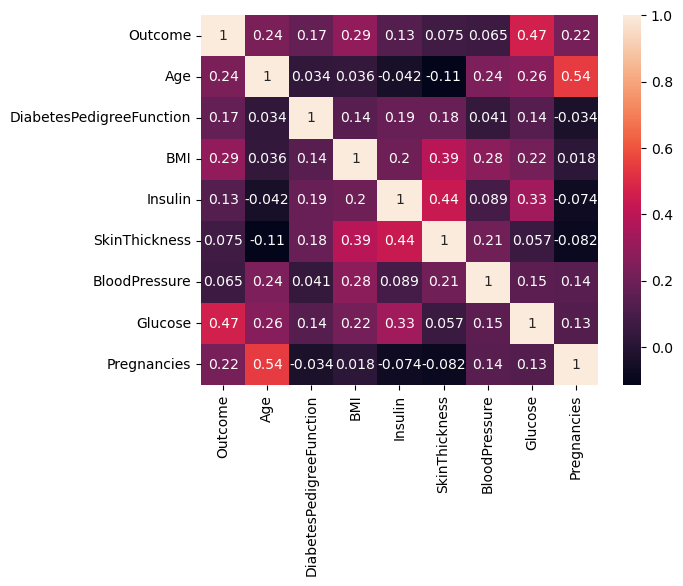

In [12]:
sns.heatmap(df[["Outcome","Age","DiabetesPedigreeFunction","BMI","Insulin","SkinThickness","BloodPressure","Glucose","Pregnancies"]].corr(),annot= True)

#### features with strong relation with target y(outcomes) 
 * Pregnancies  22%            
 * Glucose      45%                        
 * Insulin     13%              
 * BMI         29%             
 * DiabetesPedigreeFunction  17%
 * Age          24%              

In [15]:
df.head(10) 

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


### Comprehension des different features:

#### Age

In [43]:
df['Age'].value_counts().unique()
# the number is one of this values 

array([72, 63, 48, 46, 38, 35, 33, 32, 29, 24, 22, 21, 19, 18, 17, 16, 15,
       14, 13, 12, 10,  8,  7,  6,  5,  4,  3,  2,  1])

C:\Users\hp\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  func(*plot_args, **plot_kwargs)
C:\Users\hp\anaconda3\Lib\site-packages\seaborn\axisgrid.py:854: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  func(*plot_args, **plot_kwargs)


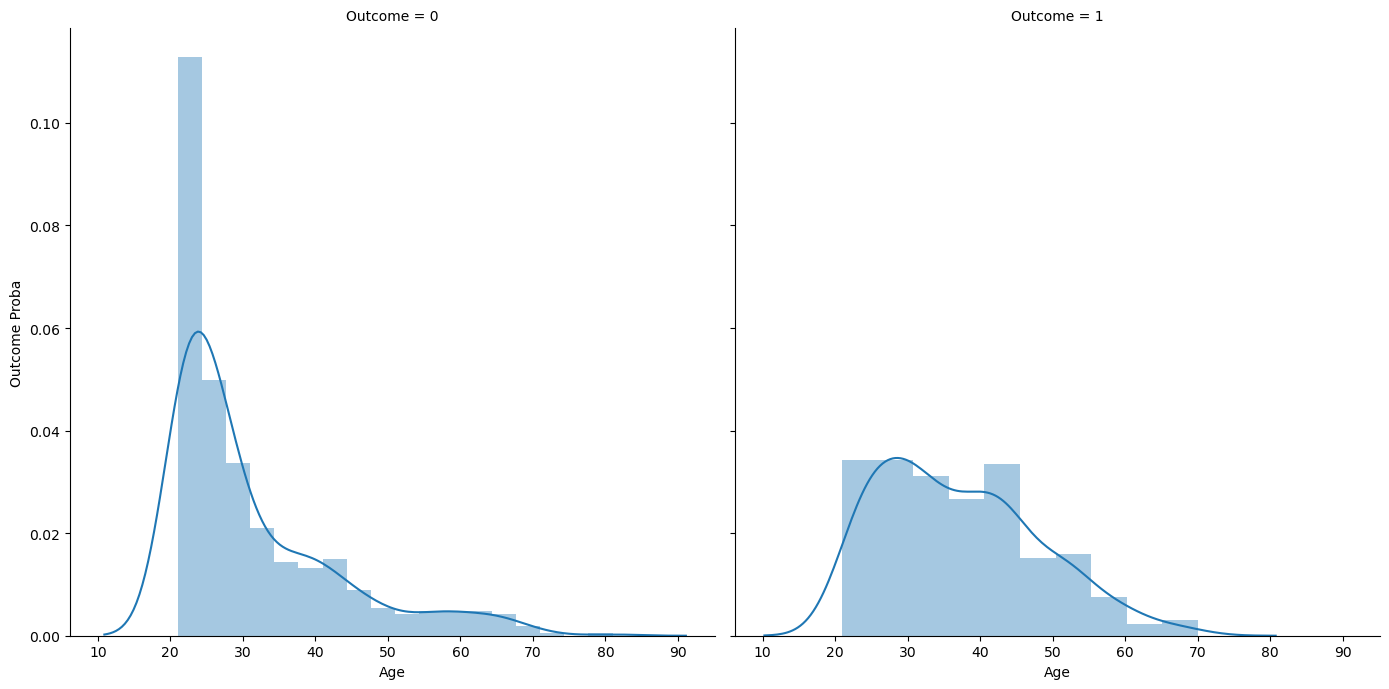

In [36]:
age_visual = sns.FacetGrid(df, col="Outcome", height=7)
age_visual = age_visual.map(sns.distplot, "Age")
age_visual = age_visual.set_axis_labels(y_var='Outcome Proba')

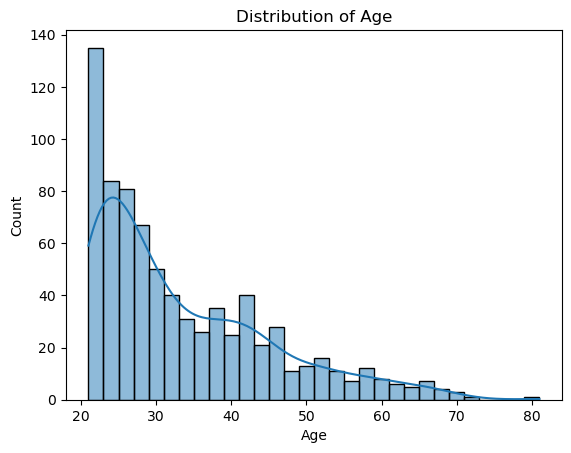

In [38]:
sns.histplot(df['Age'], bins=30, kde=True) 
plt.title("Distribution of Age")
plt.show()

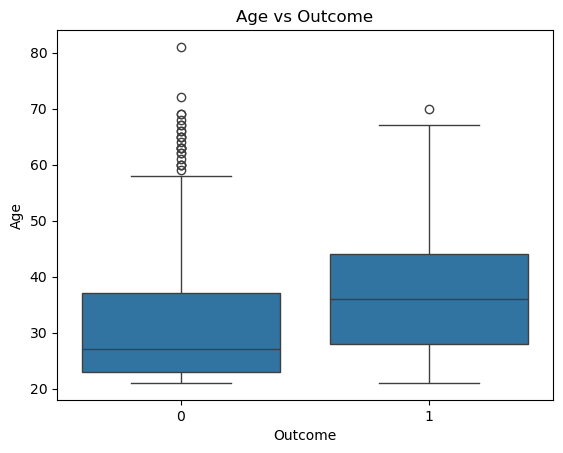

In [42]:
sns.boxplot(x="Outcome", y="Age", data=df) 
plt.title("Age vs Outcome") 
plt.show()

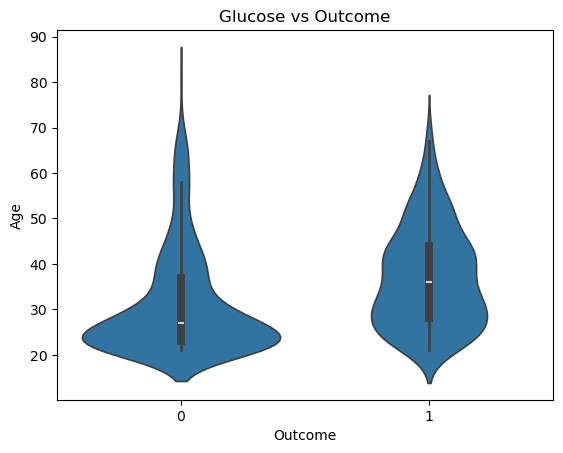

In [41]:
# Violin plot: Feature vs Target 
sns.violinplot(x="Outcome", y="Age", data=df) 
plt.title("Glucose vs Outcome") 
plt.show()

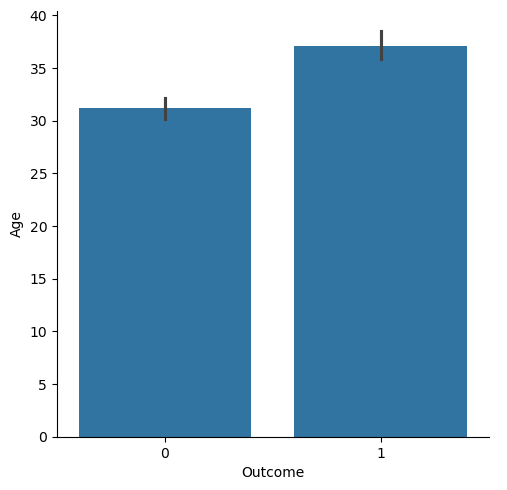

In [55]:
sns.catplot(x='Outcome' , y='Age' , data=df , kind='bar')

* young people have high chance to not get diabetes (btw 20 to 30)
* people have less chance to not get diabetes (btw 30 to 50)

#### Glucose

In [46]:
df['Glucose'].unique()

array([148,  85, 183,  89, 137, 116,  78, 115, 197, 125, 110, 168, 139,
       189, 166, 100, 118, 107, 103, 126,  99, 196, 119, 143, 147,  97,
       145, 117, 109, 158,  88,  92, 122, 138, 102,  90, 111, 180, 133,
       106, 171, 159, 146,  71, 105, 101, 176, 150,  73, 187,  84,  44,
       141, 114,  95, 129,  79,   0,  62, 131, 112, 113,  74,  83, 136,
        80, 123,  81, 134, 142, 144,  93, 163, 151,  96, 155,  76, 160,
       124, 162, 132, 120, 173, 170, 128, 108, 154,  57, 156, 153, 188,
       152, 104,  87,  75, 179, 130, 194, 181, 135, 184, 140, 177, 164,
        91, 165,  86, 193, 191, 161, 167,  77, 182, 157, 178,  61,  98,
       127,  82,  72, 172,  94, 175, 195,  68, 186, 198, 121,  67, 174,
       199,  56, 169, 149,  65, 190])

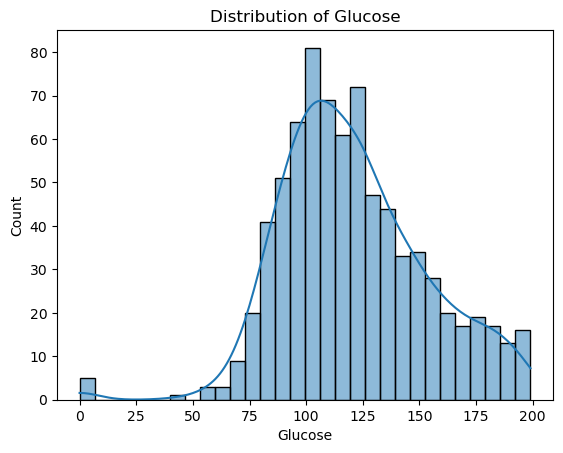

In [47]:
sns.histplot(df['Glucose'], bins=30, kde=True) 
plt.title("Distribution of Glucose")
plt.show()
# pic in glucose (btw 100 n 150)

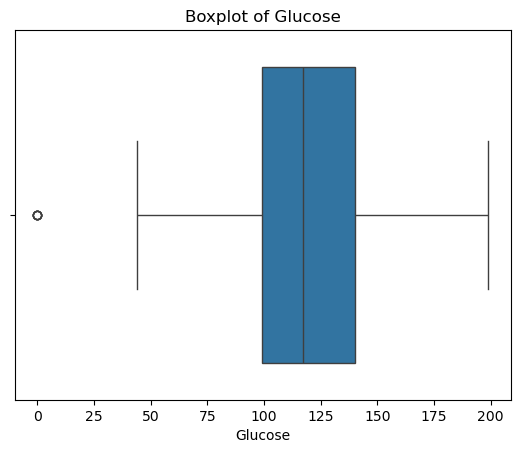

In [48]:
sns.boxplot(x=df['Glucose'])
plt.title("Boxplot of Glucose") 
plt.show()

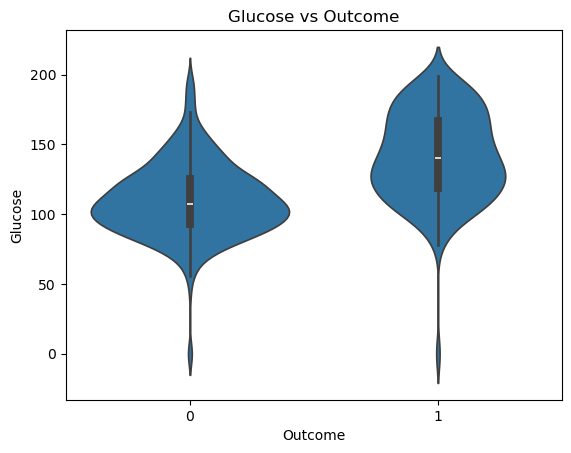

In [49]:
sns.violinplot(x="Outcome", y="Glucose", data=df) 
plt.title("Glucose vs Outcome")
plt.show()

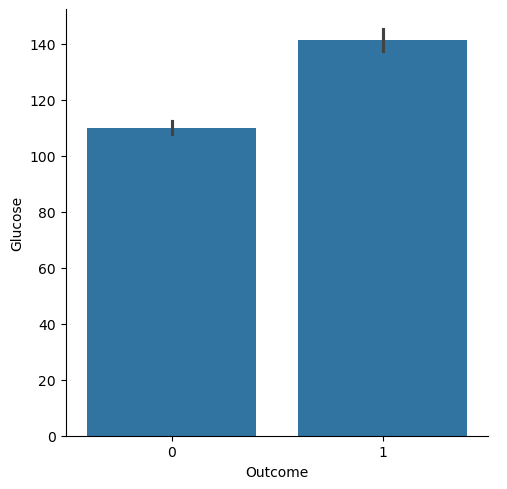

In [54]:
sns.catplot(x='Outcome' , y='Glucose' , data=df , kind='bar')

*  pic in glucose (btw 100 n 150)
* the higher the glucose the high chance to get diabtes 

#### Pregnancies 

In [51]:
df['Pregnancies'].unique()

array([ 6,  1,  8,  0,  5,  3, 10,  2,  4,  7,  9, 11, 13, 15, 17, 12, 14])

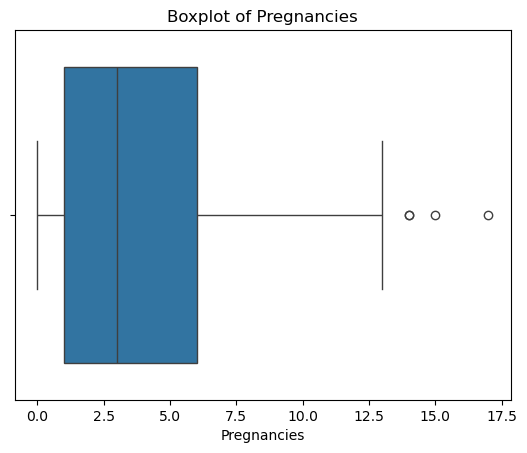

In [57]:
sns.boxplot(x=df['Pregnancies']) 
plt.title("Boxplot of Pregnancies")
plt.show() 

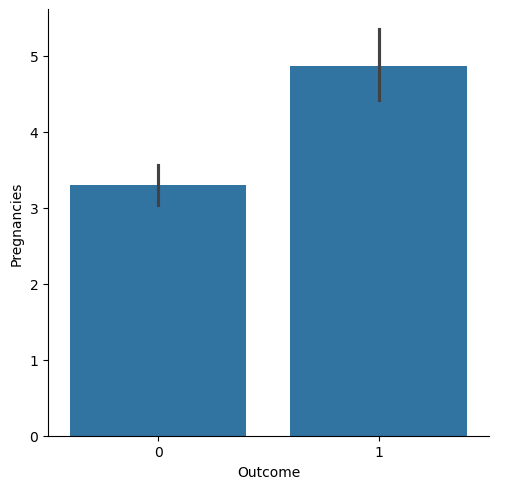

In [53]:
sns.catplot(x='Outcome' , y='Pregnancies' , data=df , kind='bar')

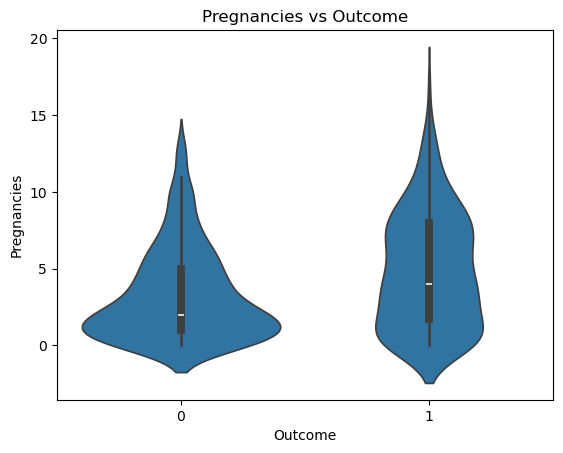

In [59]:
sns.violinplot(x="Outcome", y="Pregnancies", data=df) 
plt.title("Pregnancies vs Outcome") 
plt.show()

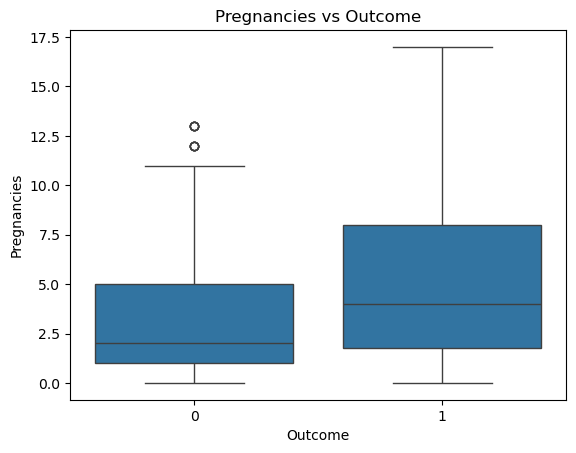

In [60]:
sns.boxplot(x="Outcome", y="Pregnancies", data=df)
plt.title("Pregnancies vs Outcome") 
plt.show()

* most Pregnancies is btw 2 to 5 have high chance to not get diabtes
* some outliers at right (people give birth to more than the normal above 10)
* our distirbution is left skewed
* the higher people give birth (pregnat)the higher the chance to get diabtes

### Insulin

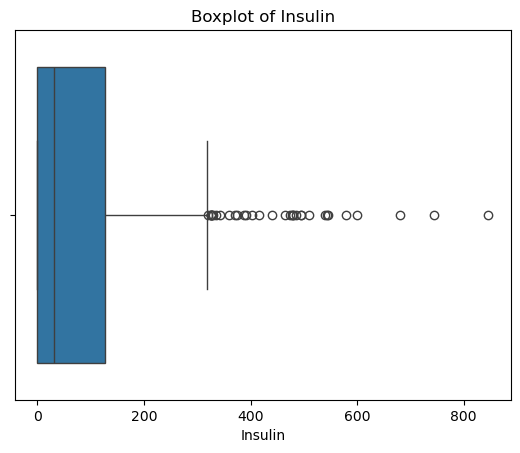

In [64]:
sns.boxplot(x=df['Insulin']) 
plt.title("Boxplot of Insulin") 
plt.show() # a lot of outliers

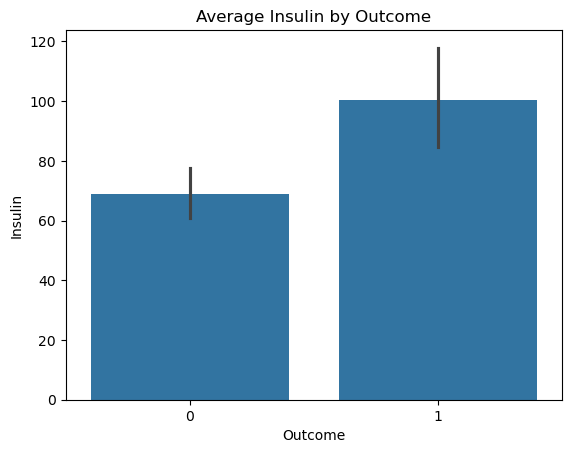

In [66]:
sns.barplot(x="Outcome", y="Insulin", data=df)
plt.title("Average Insulin by Outcome") 
plt.show()

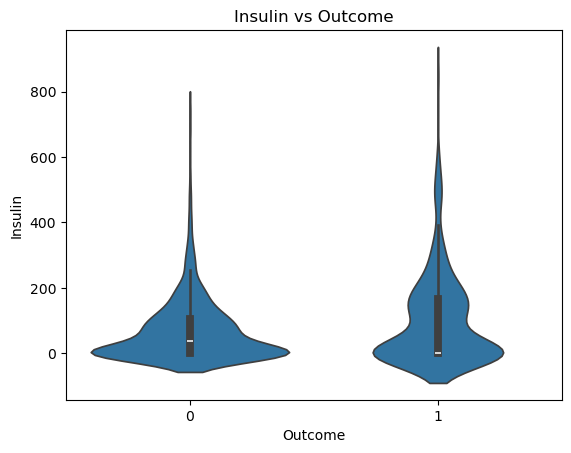

In [77]:
sns.violinplot(x="Outcome", y="Insulin", data=df) 
plt.title("Insulin vs Outcome")
plt.show()

* the higher the insulin the higher chance to get diabtes
* people with low Insulin have less chance to get diabtes 

### BMI 

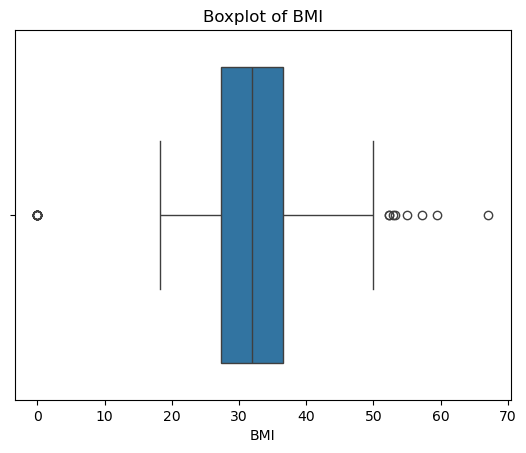

In [78]:
sns.boxplot(x=df['BMI']) 
plt.title("Boxplot of BMI") 
plt.show() #locate outliers at right , means we have left skewed (left distribution)

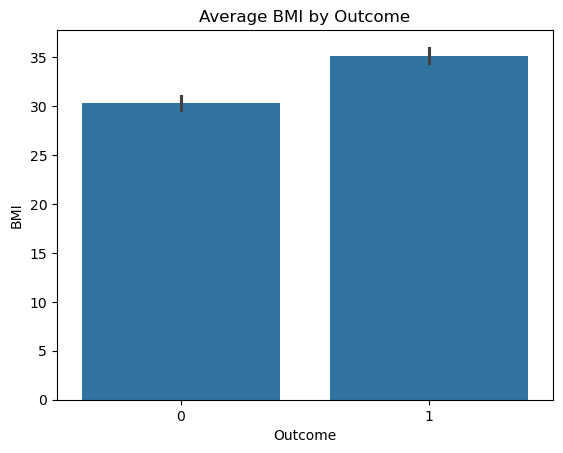

In [79]:
sns.barplot(x="Outcome", y="BMI", data=df)
plt.title("Average BMI by Outcome") 
plt.show()

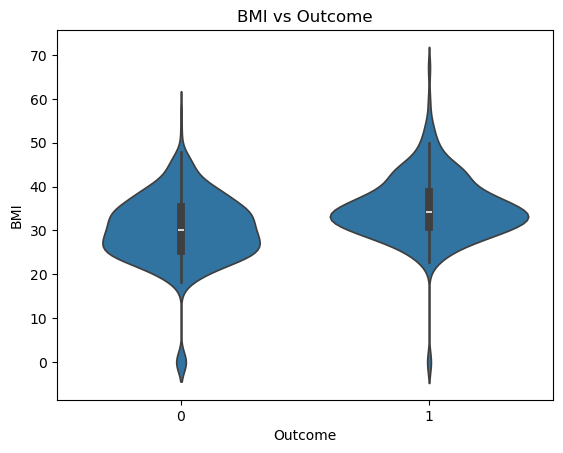

In [80]:
sns.violinplot(x="Outcome", y="BMI", data=df) 
plt.title("BMI vs Outcome")
plt.show()

* people with BMI (btw 30 n 40) have high chance to get diabtes
* locate outliers at right , means we have left skewed (left distribution)

### DiabetesPedigreeFunction 

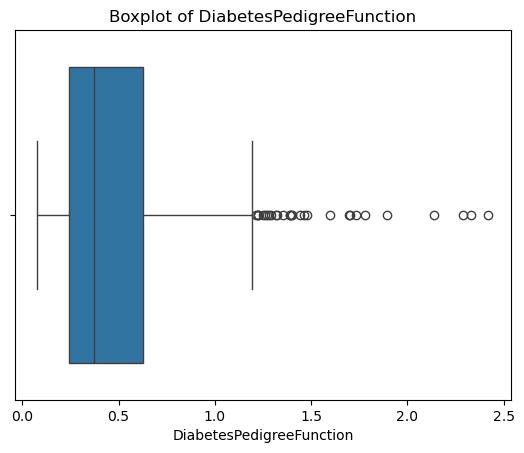

In [84]:
sns.boxplot(x=df['DiabetesPedigreeFunction']) 
plt.title("Boxplot of DiabetesPedigreeFunction") 
plt.show() # a lot of outliers

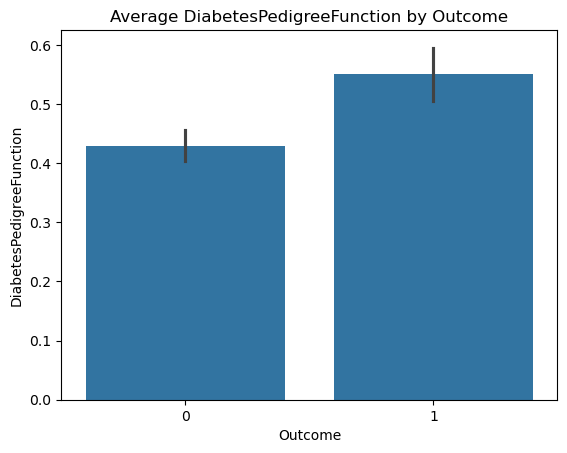

In [83]:
sns.barplot(x="Outcome", y="DiabetesPedigreeFunction", data=df)
plt.title("Average DiabetesPedigreeFunction by Outcome") 
plt.show()

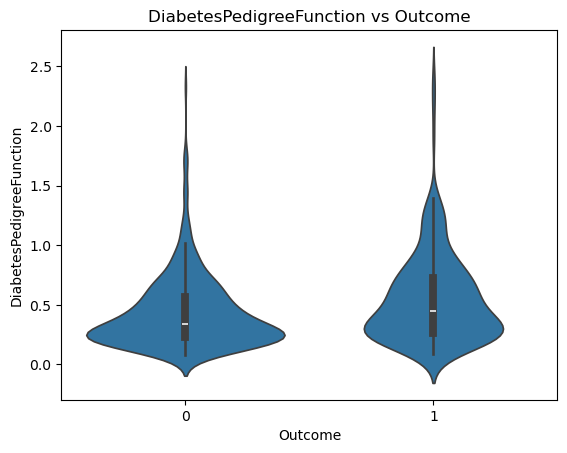

In [82]:
sns.violinplot(x="Outcome", y="DiabetesPedigreeFunction", data=df) 
plt.title("DiabetesPedigreeFunction vs Outcome")
plt.show()

* people with DiabetesPedigreeFunction (btw 0 n 0,5) have less chance to get diabtes
* locate outliers at right , means we have left skewed (left distribution) 

### Pairwise Relationships (Multiple Features vs Target)

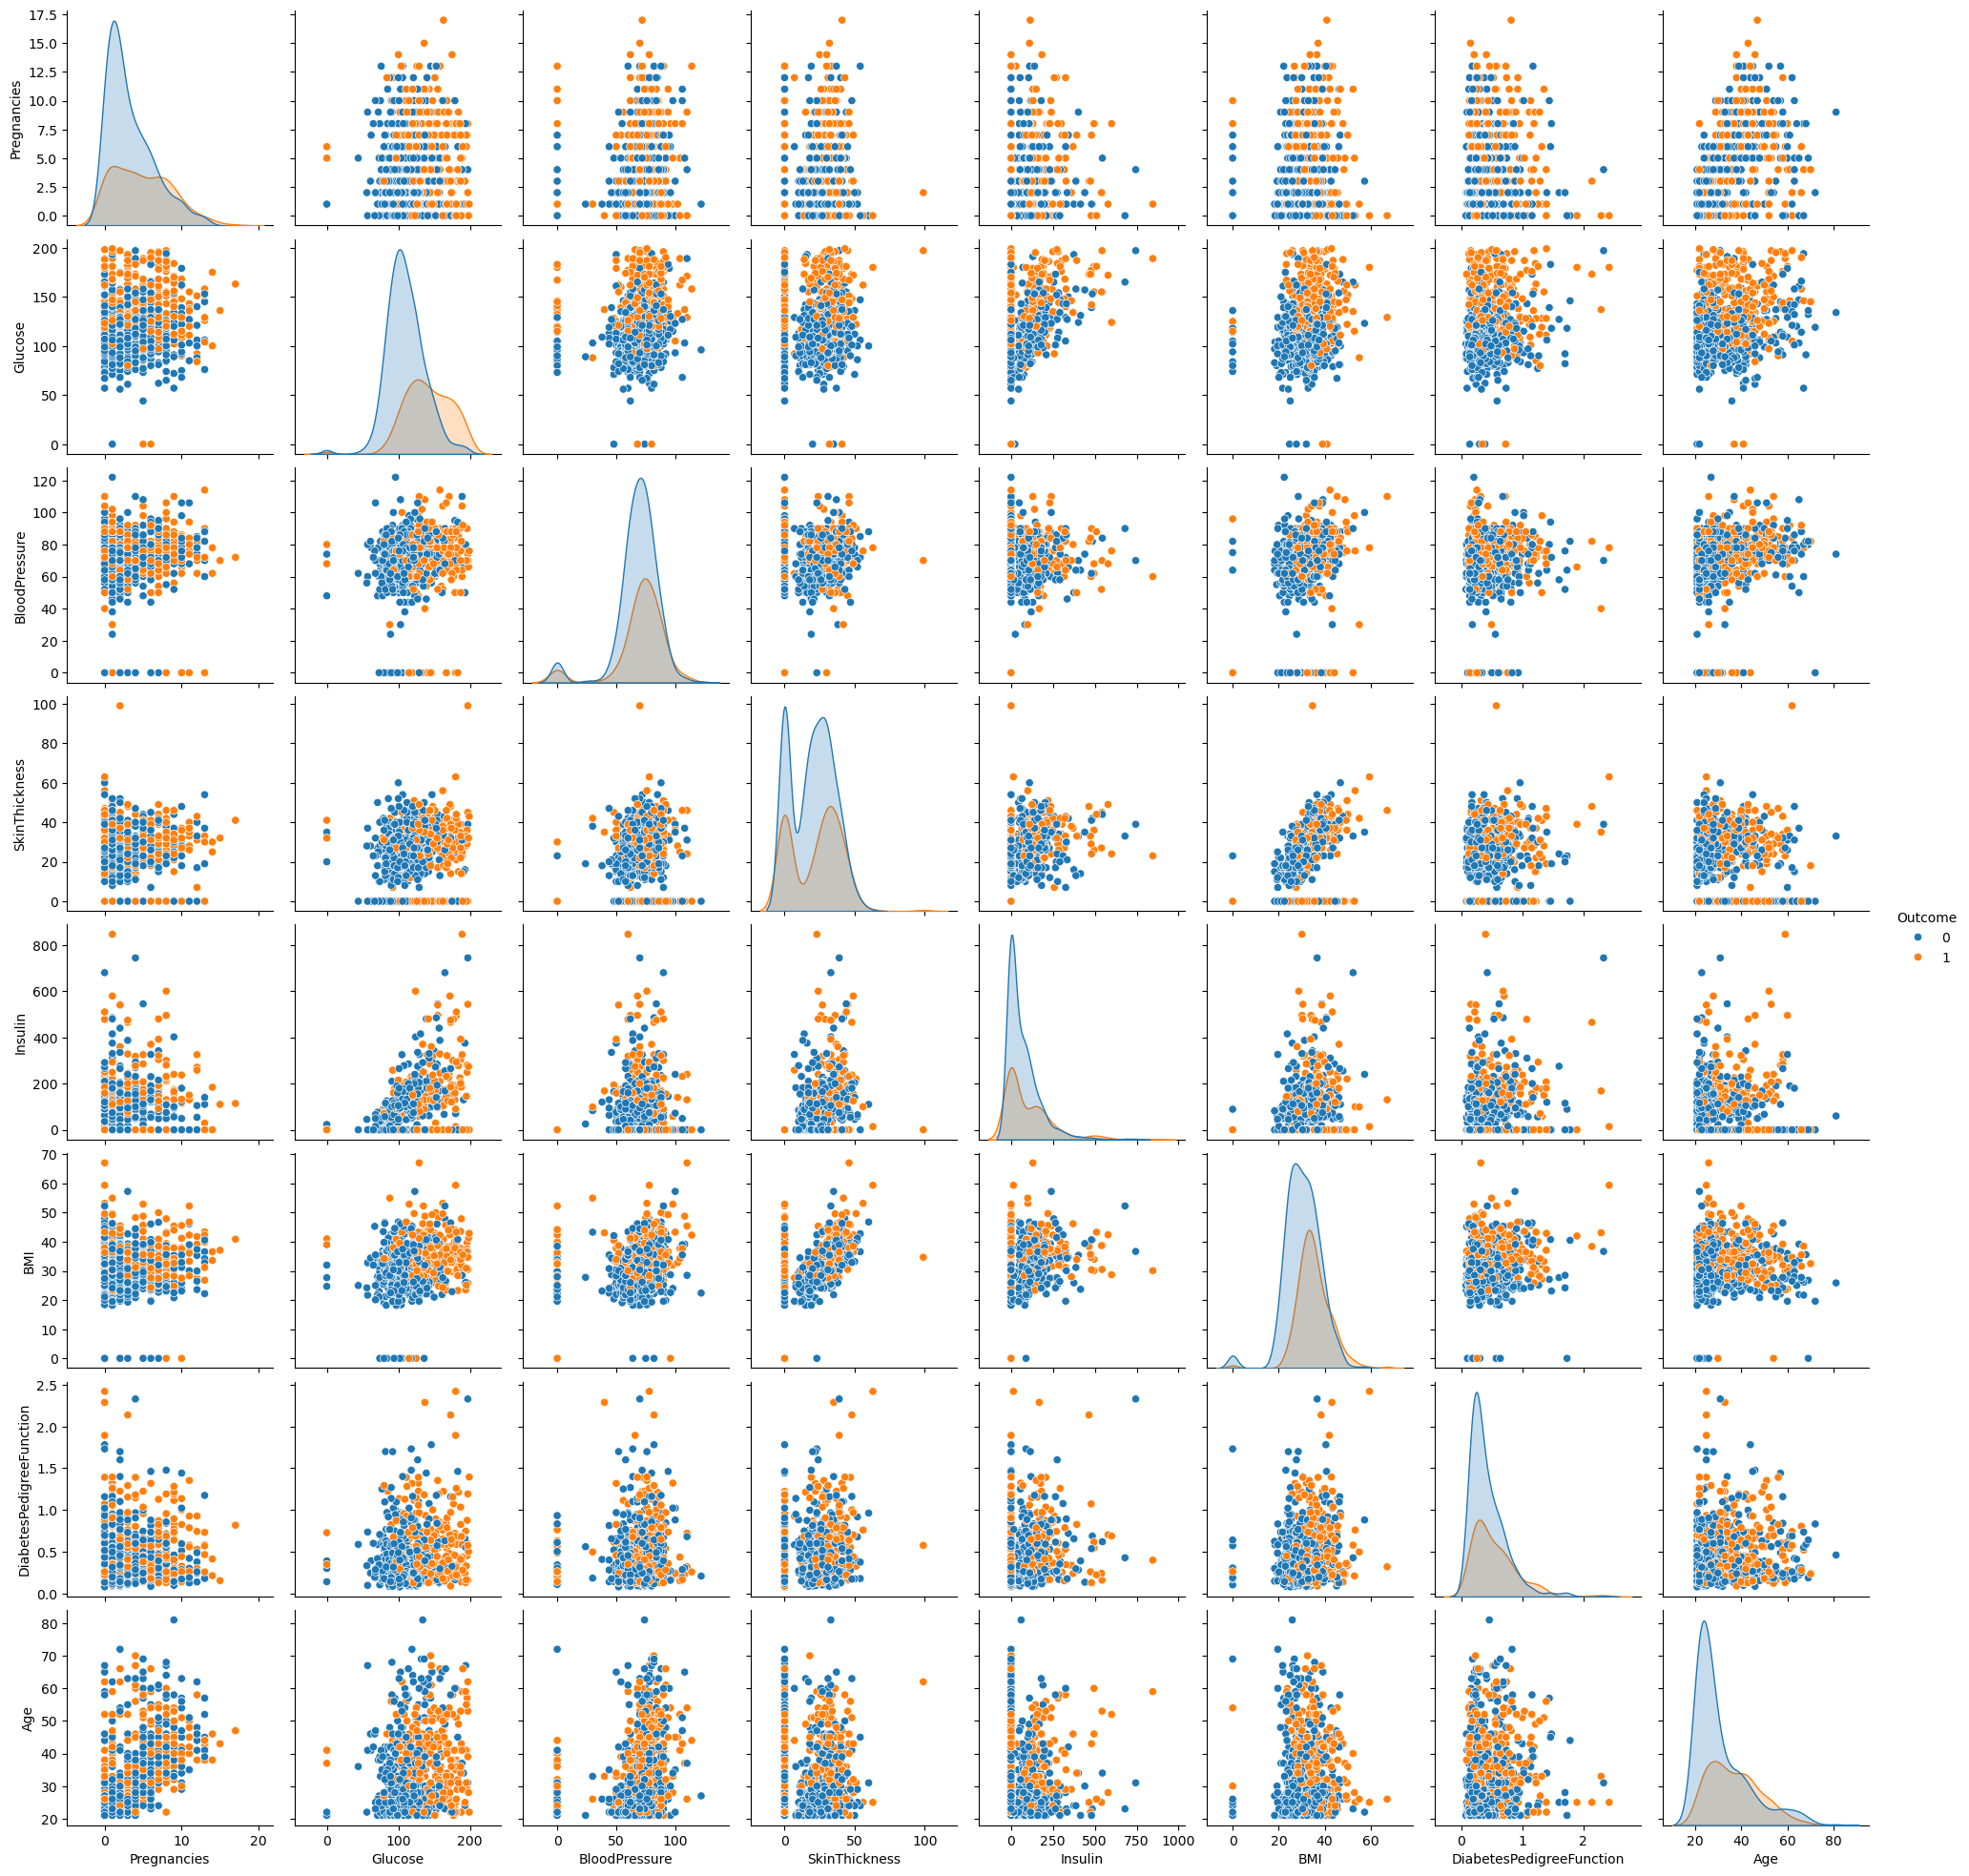

In [85]:
sns.pairplot(df, hue="Outcome") 
plt.show()

# Preprocessing 

* cree train set
* elimination des nan  (pas besoin)
* encodage (pas besoin)
* supression des outliers
* feature engenreing
* feature scaling 

In [5]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## Outliers (methodes => IQR , Zscore )

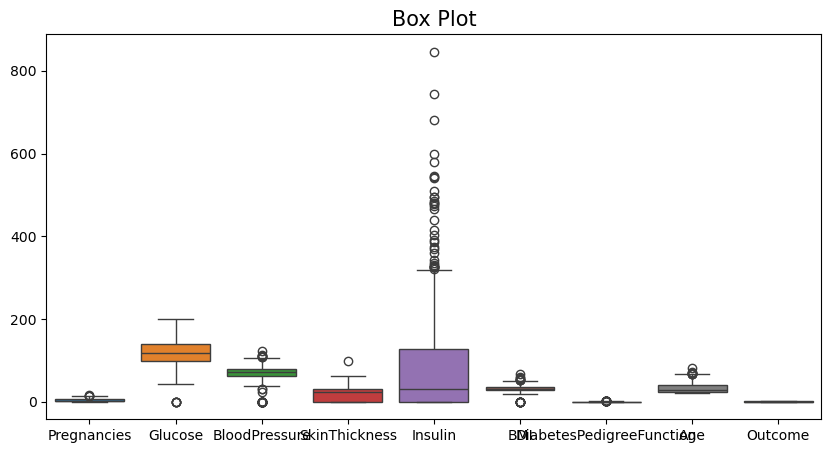

In [11]:
fig = plt.figure(figsize=(10,5))
sns.boxplot(df)
plt.title('Box Plot', fontsize=15)
plt.xlabel('', fontsize=14)
plt.show()

In [24]:
# Detecter number of outliers in each columns of data
outliers_counts = {}

for col in df.select_dtypes(include='number'):
    Q1, Q3 = df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outliers_counts[col] = count

print(outliers_counts)


{'Pregnancies': np.int64(4), 'Glucose': np.int64(5), 'BloodPressure': np.int64(45), 'SkinThickness': np.int64(1), 'Insulin': np.int64(34), 'BMI': np.int64(19), 'DiabetesPedigreeFunction': np.int64(29), 'Age': np.int64(9), 'Outcome': np.int64(0)}


##### Number of outliers in each columns :
* Pregnancies':(4),
*  'Glucose': (5),
*  'BloodPressure': (45),
* 'SkinThickness': (1),
* 'Insulin': (34),
* 'BMI': (19),
* 'DiabetesPedigreeFunction':(29),
*  'Age': (9),
*  'Outcome': (0)


In [33]:
def cap_outliers_iqr(df, columns):
    """
    Remplace les outliers par les valeurs limites IQR
    Garde toutes les lignes, juste remplace les valeurs extrêmes
    """
    df_clean = df.copy()
    
    for col in columns:
        if col in df_clean.columns:
            Q1 = df_clean[col].quantile(0.25)
            Q3 = df_clean[col].quantile(0.75)
            IQR = Q3 - Q1
            
            lower = Q1 - 1.5 * IQR
            upper = Q3 + 1.5 * IQR
            
            # Vérifier s'il y a des outliers
            outliers_before = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
            if outliers_before > 0:
                print(f"{col}: {outliers_before} outliers remplacés")
            
            # Remplace les outliers par les limites
            df_clean[col] = df_clean[col].clip(lower, upper)
    
    return df_clean

In [34]:
# Liste de tes colonnes
columns_to_treat = ['Pregnancies', 'Glucose', 'BloodPressure', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

# 1. Vérifier quelles colonnes existent dans ton dataframe
existing_columns = [col for col in columns_to_treat if col in df.columns]
print(f"Colonnes à traiter: {existing_columns}")

# 2. Vérifier les outliers avant traitement
print("\n=== Outliers avant traitement ===")
for col in existing_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers_count = ((df[col] < lower) | (df[col] > upper)).sum()
    if outliers_count > 0:
        print(f"{col}: {outliers_count} outliers")

# 3. Appliquer la fonction de traitement
df_clean = cap_outliers_iqr(df, existing_columns)

# 4. Vérifier après traitement
print("\n=== Vérification après traitement ===")
print(f"Taille du dataset: {len(df_clean)} lignes (identique à avant)")
print(f"Colonnes traitées: {len(existing_columns)} colonnes")

Colonnes à traiter: ['Pregnancies', 'Glucose', 'BloodPressure', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

=== Outliers avant traitement ===
Pregnancies: 4 outliers
Glucose: 5 outliers
BloodPressure: 45 outliers
Insulin: 34 outliers
BMI: 19 outliers
DiabetesPedigreeFunction: 29 outliers
Age: 9 outliers
Pregnancies: 4 outliers remplacés
Glucose: 5 outliers remplacés
BloodPressure: 45 outliers remplacés
Insulin: 34 outliers remplacés
BMI: 19 outliers remplacés
DiabetesPedigreeFunction: 29 outliers remplacés
Age: 9 outliers remplacés

=== Vérification après traitement ===
Taille du dataset: 768 lignes (identique à avant)
Colonnes traitées: 7 colonnes


In [38]:
columns_to_treat = ['Pregnancies', 'Glucose', 'BloodPressure', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

for col in existing_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers_count = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    if outliers_count > 0:
        print(f"{col}: {outliers_count} outliers")

print(outliers_count) # we cleaned our data from outliers

0


<Axes: >

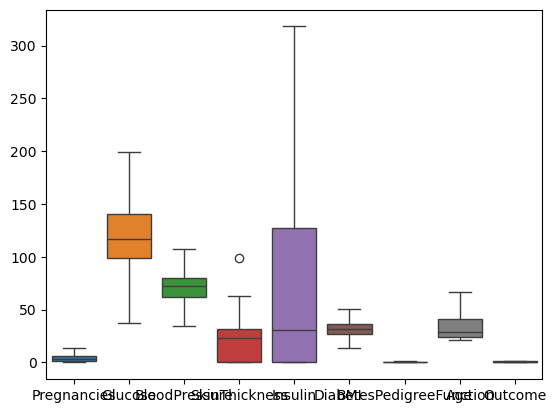

In [40]:
sns.boxplot(df_clean) #boxplot to visualise the distrubution of data

## feature engenreing

* add glucose_bmi = Glucose * BMI
* add pressure_age = BloodPressure * Age
* add insulin_glucose_ratio = Insulin / Glucose + 1

In [41]:
# Interactions physiologiques importantes

df_clean['glucose_bmi'] = df_clean['Glucose'] * df_clean['BMI']

df_clean['pressure_age'] = df_clean['BloodPressure'] * df_clean['Age']

df_clean['insulin_glucose_ratio'] = df_clean['Insulin'] / (df_clean['Glucose'] + 1)

In [43]:
df_clean.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,glucose_bmi,pressure_age,insulin_glucose_ratio
0,6.0,148.0,72,35,0.0,33.6,0.627,50.0,1,4972.8,3600.0,0.000000
1,1.0,85.0,66,29,0.0,26.6,0.351,31.0,0,2261.0,2046.0,0.000000
2,8.0,183.0,64,0,0.0,23.3,0.672,32.0,1,4263.9,2048.0,0.000000
3,1.0,89.0,66,23,94.0,28.1,0.167,21.0,0,2500.9,1386.0,1.044444
4,0.0,137.0,40,35,168.0,43.1,1.200,33.0,1,5904.7,1320.0,1.217391


## Splitting data

In [48]:
df_clean.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,glucose_bmi,pressure_age,insulin_glucose_ratio
0,6.0,148.0,72,35,0.0,33.6,0.627,50.0,1,4972.8,3600.0,0.000000
1,1.0,85.0,66,29,0.0,26.6,0.351,31.0,0,2261.0,2046.0,0.000000
2,8.0,183.0,64,0,0.0,23.3,0.672,32.0,1,4263.9,2048.0,0.000000
3,1.0,89.0,66,23,94.0,28.1,0.167,21.0,0,2500.9,1386.0,1.044444
4,0.0,137.0,40,35,168.0,43.1,1.200,33.0,1,5904.7,1320.0,1.217391


In [49]:
X = df_clean.drop(df_clean.columns[[8]], axis= 1) # splitting the features X
y = df_clean['Outcome'] #splitting the target Y 

In [50]:
X.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,glucose_bmi,pressure_age,insulin_glucose_ratio
0,6.0,148.0,72,35,0.0,33.6,0.627,50.0,4972.8,3600.0,0.000000
1,1.0,85.0,66,29,0.0,26.6,0.351,31.0,2261.0,2046.0,0.000000
2,8.0,183.0,64,0,0.0,23.3,0.672,32.0,4263.9,2048.0,0.000000
3,1.0,89.0,66,23,94.0,28.1,0.167,21.0,2500.9,1386.0,1.044444
4,0.0,137.0,40,35,168.0,43.1,1.200,33.0,5904.7,1320.0,1.217391


In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20)

## Feature scalling

In [54]:
from sklearn.preprocessing import StandardScaler

sc_x = StandardScaler()
X_train = sc_x.fit_transform(X_train)
X_test = sc_x.transform(X_test)

# Modelling (for binary classification problem)

In [55]:
# lets start building our model

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import SVC     

In [56]:
# Starting by building the models

logreg = LogisticRegression()

dt_classifier = DecisionTreeClassifier()

rf_classifier = RandomForestClassifier(n_estimators=1000 , criterion='entropy' , random_state=0)   

knn_classifier = KNeighborsClassifier()
 
svc_classifier = SVC()

In [57]:
# now we gonna fit/train our train set in our model 

logreg.fit(X_train , y_train)

dt_classifier.fit(X_train , y_train) 

rf_classifier.fit(X_train , y_train)

knn_classifier.fit(X_train , y_train)

svc_classifier.fit(X_train , y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [58]:
# now lets predict/Evaluate the test set 

logreg_pred = logreg.predict(X_test)

dt_classifier_pred = dt_classifier.predict(X_test)

rf_classifier_pred = rf_classifier.predict(X_test)

knn_classifier_pred = knn_classifier.predict(X_test)

svc_classifier_pred = svc_classifier.predict(X_test)

In [59]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [61]:
print("Logistic Regression Accuracy:", accuracy_score(y_test, logreg_pred)) # 75%

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_classifier_pred)) # 71%

print("Random Forest Accuracy:", accuracy_score(y_test, rf_classifier_pred)) # 75% 

print("KNN Accuracy:", accuracy_score(y_test, knn_classifier_pred)) #73%

print("SVC Accuracy:", accuracy_score(y_test, svc_classifier_pred)) #78% 

Logistic Regression Accuracy: 0.7532467532467533
Decision Tree Accuracy: 0.7142857142857143
Random Forest Accuracy: 0.7532467532467533
KNN Accuracy: 0.7337662337662337
SVC Accuracy: 0.7857142857142857


# Conclusion :
* Model SVC give the high accuracy score with 75% of our test set 

In [66]:
from sklearn.metrics import ConfusionMatrixDisplay

📊 Scores:
LogReg: 75.32%
DT: 71.43%
RF: 75.32%
KNN: 73.38%
SVC: 78.57%


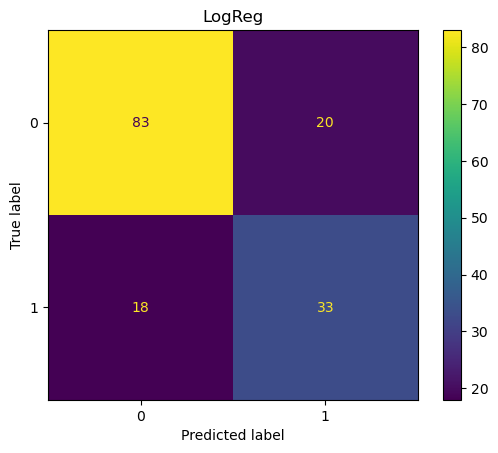

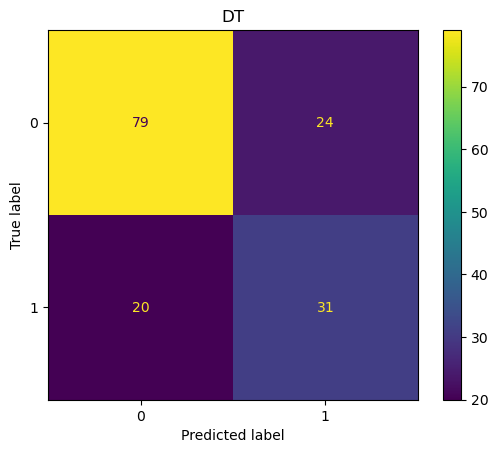

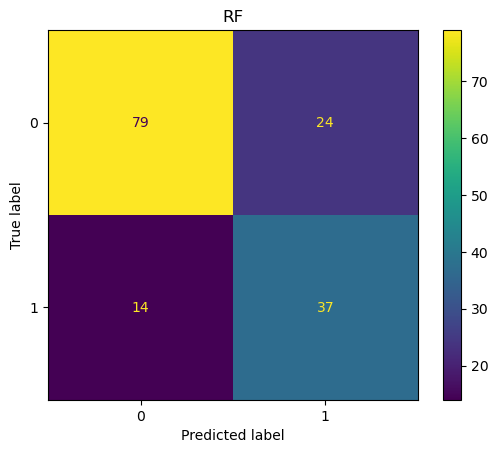

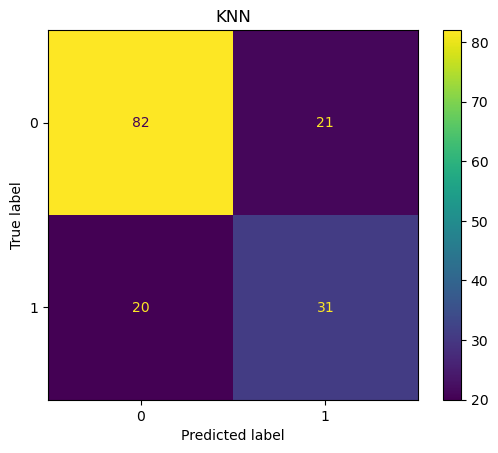

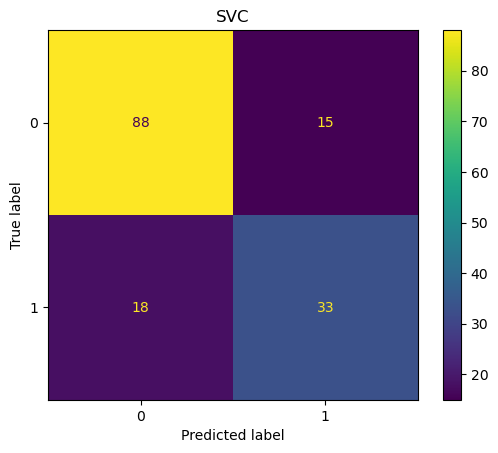

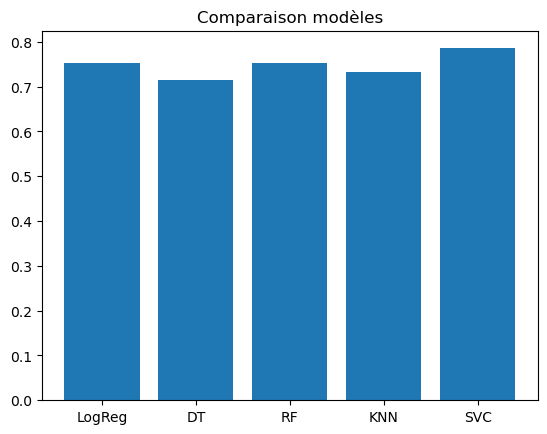

In [67]:
# Scores individuels
print("📊 Scores:")
print(f"LogReg: {logreg.score(X_test, y_test):.2%}")
print(f"DT: {dt_classifier.score(X_test, y_test):.2%}")
print(f"RF: {rf_classifier.score(X_test, y_test):.2%}")
print(f"KNN: {knn_classifier.score(X_test, y_test):.2%}")
print(f"SVC: {svc_classifier.score(X_test, y_test):.2%}")

# Matrices de confusion (Boucle sur chaque modèle + Crée la matrice de confusion )
for name, model in [("LogReg",logreg), ("DT",dt_classifier), ("RF",rf_classifier), 
                    ("KNN",knn_classifier), ("SVC",svc_classifier)]:
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test))
    plt.title(name)
    plt.show()

# Comparaison finale
scores = [logreg.score(X_test, y_test), dt_classifier.score(X_test, y_test),
          rf_classifier.score(X_test, y_test), knn_classifier.score(X_test, y_test),
          svc_classifier.score(X_test, y_test)]

plt.bar(["LogReg","DT","RF","KNN","SVC"], scores)
plt.title("Comparaison modèles")
plt.show()